In [19]:
# Loading all of the relevant things:
import torch
import matplotlib.pyplot as plt
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()
words[len(words) - 1000: len(words) - 990]
chars =sorted(list(set(''.join(words)))) # sorted list of all the characters
s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0 # explicit mapping for special character
i_to_s = {}
for s, i in s_to_i.items():
    i_to_s[i] = s

## What the Neural Network approach to the bigram model does:
- we input it a character
- it has internal weights and parameteres configured
- it outputs a probability distribution over all the characters that are likely to be followed after the input character
- since we have the loss function (avg negative log likelihood) in order to evaluate and improve our neural net (gradient descent-based optimization)
- 

In [20]:
# 1. Create the training set for all bigrams (x, y):

xs = [] # input sets, integers
ys = [] # targets / labels

for w in words[:1]:
    # sliding it through the words 2 char at a time:
    chars = ['.'] + list(w) + ['.'] # adding a start and end character
    
    for char_1, char_2 in zip(chars, chars[1:]): # two at a time
        char1_idx = s_to_i[char_1]
        char2_idx = s_to_i[char_2]
        print(char_1, char_2)
        xs.append(char1_idx)
        ys.append(char2_idx)
print("these are five examples (first name with 5 examples for the bigram) for our neural net right here")

# turning into tensors for efficiency later on
xs = torch.tensor(xs)
ys = torch.tensor(ys)

. e
e m
m m
m a
a .
these are five examples (first name with 5 examples for the bigram) for our neural net right here


## Inputs:
- bole to xs
- means, what we will be inputting to the neural network model, as an array (we'll be feeding these one by one)

## Target / Label:
- bole to ys
- for ith index of input in xs\[i], we want the result to come out to be ys[i]
- bole to, agar first index is input e in xs, and ys first index is m, then when inputted with e, the neural network's target output should be m

In [21]:
print(xs)
print(ys)
# this just means, if 0 is inputted, it should have a high proba of 5
# 5 input, high proba for 13
# and so on

tensor([ 0,  5, 13, 13,  1])
tensor([ 5, 13, 13,  1,  0])


## Input for this neural network (one-hot encoding):
- the neural network takes a vector of characters, and we will make this vector one-hot
- What a one-hot vector is that all rows in the column vector are 0s, and whatever you want the input to be is 1
- So example if you want to input the 13th letter (m), you would enter a column vector (or just a vector) with all 0s, but the 13th index is 1.

Here, we get 5 vectors, each serving as an input to the neural network
tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])
torch.Size([5, 27])


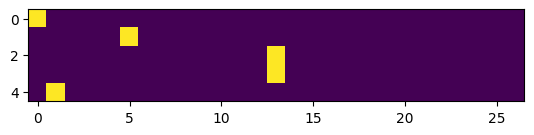

In [22]:
import torch.nn.functional as F
x_encoded = F.one_hot(xs, num_classes=27).float() # encoded inputs, casted to float for neural nets
print("Here, we get 5 vectors, each serving as an input to the neural network")
print(x_encoded)
print(x_encoded.shape)
plt.imshow(x_encoded)

In [23]:
x_encoded.dtype

torch.float32

In [24]:
# one neuron version of the first layer calculations (simplified) from the inputs:
W = torch.randn((27, 1)) # a column vector with 27 values of the weights of the first layer neuron
# randn just means randomly sampling according to the normal distribution

dot_prod = x_encoded @ W # dot product between inputs and weights)
# (5x27) dot (27, 1)

# why he does this instead of a standard W dot x (in Wx + b):
# he made the x_encoded (usually a column vector for single pass) into a series of row vectors
# what it allows him to do is to process multiple inputs through the neural networks in parallel

# doing this dot product leads to a (5x1) matrix
dot_prod

# where, each entry in this column vector is the Wx result of each one of those inputs,
# calculated in parallel (without having to do forward pass for each one of the inputs)
# This is the reason why he didn't use W @ x_encoded (like dimension corrected individual version)

tensor([[ 0.9007],
        [-1.2004],
        [-0.2133],
        [-0.2133],
        [-0.7635]])

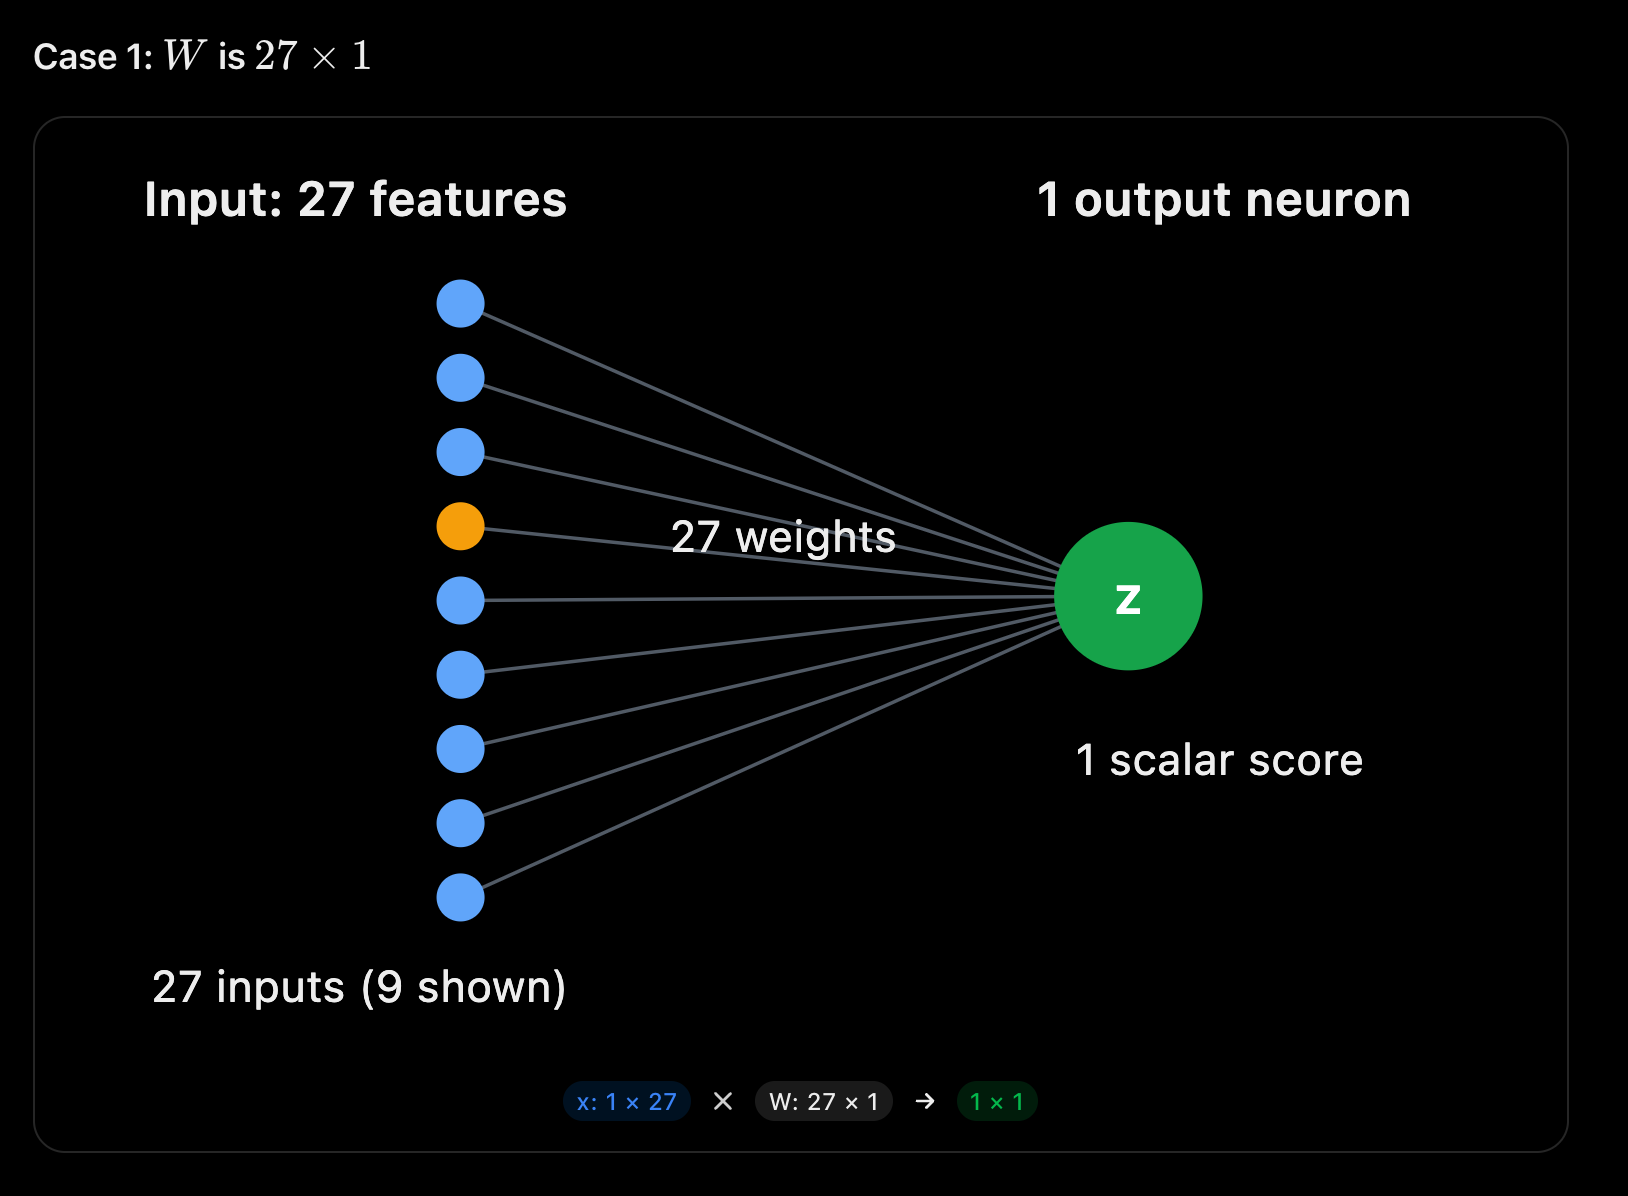

In [25]:
# 27 neurons instead of 1 neuron (27 neurons in the first layer):
W = torch.randn((27, 27))

dot_prod = x_encoded @ W
print("dimensions:", dot_prod.shape)

dot_prod[3,13] # gives the firing rate of the 13th neuron looking at the 3rd input

dimensions: torch.Size([5, 27])


tensor(-0.1735)

In [26]:
# How this is working a bit more clearly if still confused on the matrix multiplication part:

# this:
print(dot_prod[3,13]) # gives the firing rate of the 13th neuron looking at the 3rd input

# will be the same as:
print((W[:, 13] * x_encoded[3]).sum()) # because this is literally W dot x,
# therefore, the activation of the 13th neuron

tensor(-0.1735)
tensor(-0.1735)


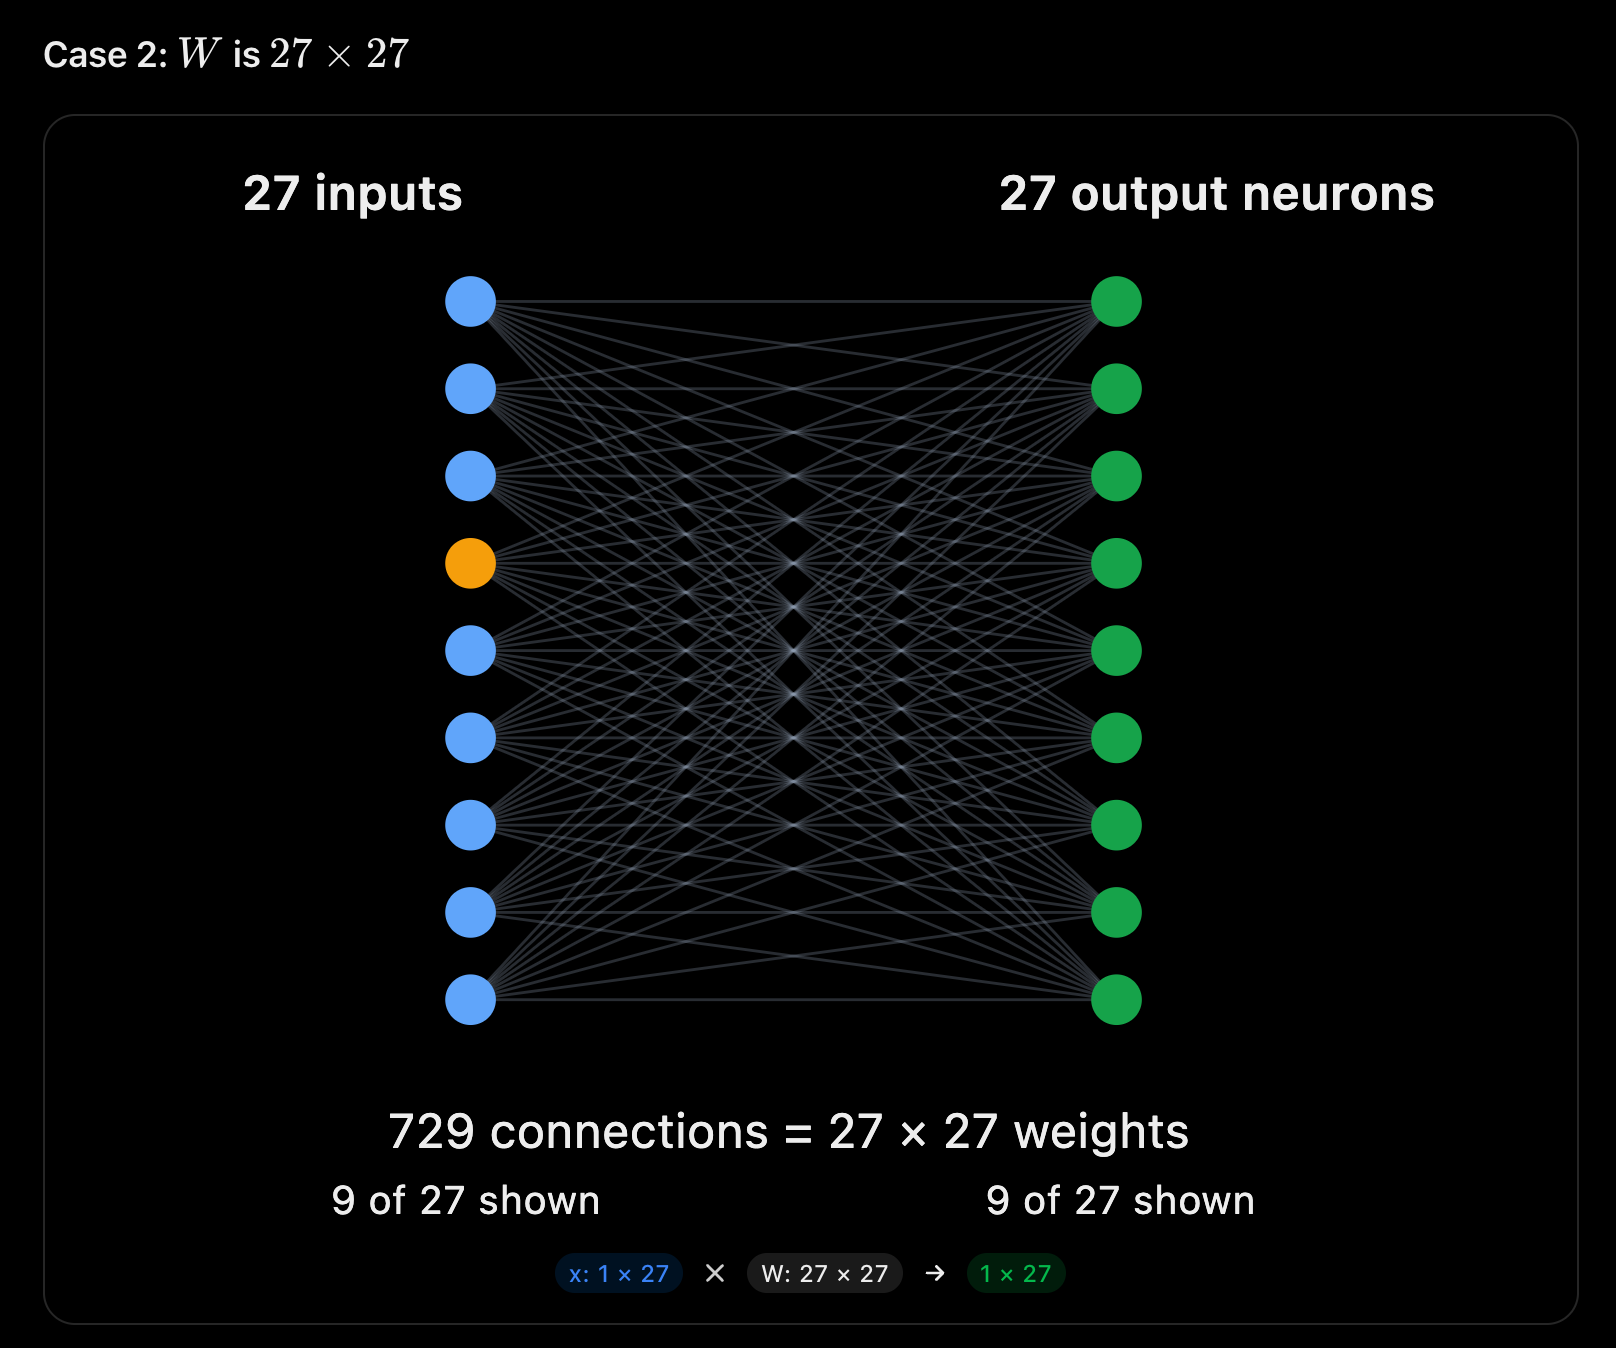

We're not going to be implementing the following for this simple example:
- biases
- activation functions
- more hidden layers

Just gonna have 27 input neurons, 27 neurons in a single hidden layer, and 27 output neurons

Expectations vs reality of traditional approach to outputs:

- some sort of probability distribution over the 27 letters
- since its a probability distribution, the sum of all floats of the output layer should sum to 1
    - neural nets don't have that ability to guarantee that all the outputs sum to 1
    - the dot product produces both negative and positive numbers, how are we going to accomodate negatives using proba?

Our output approach instead (SOFTMAX):
- interpret the output as if it's `log of counts`
- once we treat the output like `log of counts`, we can do operations ourselves to turn it into probability distribution like so:
- Note: all of the things that we'll do in the code block below is differentiable, therefore it can be optimized using the backpropagation pass

In [27]:
# PROCESS OF SOFTMAX:
# softmax is basically taking a bunch of numbers (+ve or -ve) and produces a probability output that sums to 1

logits = x_encoded @ W # logits ~ log of counts, what we're interpreting each of the outputs from the NN as

counts = logits.exp() # turning logits (can be negative or positive) into counts (not actually counts, but a representative of it)
# counts is between 0 and infinity, and it is like e^(log of counts) ~ counts ("fake counts", just represents what would be counts), but gets rid of negative values
# this step can be called "logits exponentiated"

# now that the negative values are sorted with, it's gonna be super easy to normalize to make a probability plot:
probs = counts / counts.sum(1, keepdims=True)
print("probability distributions for each of the 5 input example runs", probs.shape)
print()
print(probs)
print()
print("we got over limitation of NN by this process:", probs[0].sum())

probability distributions for each of the 5 input example runs torch.Size([5, 27])

tensor([[0.0355, 0.0541, 0.0166, 0.0235, 0.0209, 0.0222, 0.0064, 0.0060, 0.0038,
         0.0028, 0.0221, 0.1076, 0.0357, 0.0140, 0.0201, 0.0280, 0.0231, 0.0198,
         0.0071, 0.0279, 0.0478, 0.2563, 0.0178, 0.0429, 0.0456, 0.0431, 0.0494],
        [0.0070, 0.0151, 0.0361, 0.1140, 0.0293, 0.0133, 0.0222, 0.0291, 0.0112,
         0.0300, 0.0916, 0.0722, 0.0062, 0.0777, 0.2559, 0.0134, 0.0082, 0.0114,
         0.0715, 0.0023, 0.0080, 0.0155, 0.0058, 0.0191, 0.0051, 0.0176, 0.0113],
        [0.0078, 0.0678, 0.0555, 0.0209, 0.0350, 0.0207, 0.0475, 0.0491, 0.0131,
         0.0470, 0.0292, 0.0264, 0.0831, 0.0183, 0.0523, 0.0383, 0.0548, 0.0221,
         0.0175, 0.0670, 0.0498, 0.0115, 0.0095, 0.0157, 0.0282, 0.0955, 0.0164],
        [0.0078, 0.0678, 0.0555, 0.0209, 0.0350, 0.0207, 0.0475, 0.0491, 0.0131,
         0.0470, 0.0292, 0.0264, 0.0831, 0.0183, 0.0523, 0.0383, 0.0548, 0.0221,
         0.0175, 0.067

In [33]:
# Code example of deriving the loss value using a pass of our neural net:

neg_log_likelihoods = [] # just for the example of emma
for i in range(5):
    x = xs[i].item() # input
    y = ys[i].item() # target

    print("-----------------------------------------")
    print(f'bigram example: {i_to_s[x]}{i_to_s[y]}')
    print(f'input: char {i_to_s[x]} index {x}')
    print(f'output proba from the neural net: {probs[i]}')
    print(f'target: char {i_to_s[y]}, index {y}')
    actual_proba_of_target = probs[i, y]
    print(f'actual probability of next char being target actually: {actual_proba_of_target}')
    log_proba = torch.log(actual_proba_of_target)
    print(f'log likelihood: {log_proba}')
    nll = log_proba
    print(f'negative log likelihood: {nll}')
    neg_log_likelihoods.append(nll.item())

print("==============================================")
print('all negative log likelihoods', neg_log_likelihoods)
print('average negative log likelihood, i.e. LOSS =', neg_log_likeli


-----------------------------------------
bigram example: .e
input: char . index 0
output proba from the neural net: tensor([0.0355, 0.0541, 0.0166, 0.0235, 0.0209, 0.0222, 0.0064, 0.0060, 0.0038,
        0.0028, 0.0221, 0.1076, 0.0357, 0.0140, 0.0201, 0.0280, 0.0231, 0.0198,
        0.0071, 0.0279, 0.0478, 0.2563, 0.0178, 0.0429, 0.0456, 0.0431, 0.0494])
target: char e, index 5
actual probability of next char being target actually: 0.022150691598653793
log likelihood: -3.8098864555358887
negative log likelihood: -3.8098864555358887
-----------------------------------------
bigram example: em
input: char e index 5
output proba from the neural net: tensor([0.0070, 0.0151, 0.0361, 0.1140, 0.0293, 0.0133, 0.0222, 0.0291, 0.0112,
        0.0300, 0.0916, 0.0722, 0.0062, 0.0777, 0.2559, 0.0134, 0.0082, 0.0114,
        0.0715, 0.0023, 0.0080, 0.0155, 0.0058, 0.0191, 0.0051, 0.0176, 0.0113])
target: char m, index 13
actual probability of next char being target actually: 0.07767486572265625
log